# CASA-AI YOLOv11 Training

This notebook contains the complete training pipeline for the sperm detection model using Ultralytics YOLOv11 Nano.
Model YOLOv11 Nano dipilih karena sangat ringan dan optimal untuk dijalankan di GPU Laptop dengan VRAM terbatas (4GB).

In [1]:
# Install dependencies if you haven't already
!pip install -r requirements.txt
!pip install ultralytics


[notice] A new release of pip is available: 25.3 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.3 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import torch
from ultralytics import YOLO

# Check CUDA availability
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device: {torch.cuda.get_device_name(0)}")

CUDA Available: True
Device: NVIDIA GeForce RTX 3050 Laptop GPU


In [3]:
# Load a COCO-pretrained YOLOv11 Nano model (Paling ringan, anti-overheat)
model = YOLO('yolo11n.pt')

# Display model info
model.info()

YOLO11n summary: 181 layers, 2,624,080 parameters, 0 gradients, 6.6 GFLOPs


(181, 2624080, 0, 6.614336)

In [4]:
results = model.train(
    data='dataset/dataset.yaml',
    epochs=50,
    imgsz=640,
    batch=8,         # Tetap 8 agar VRAM adem dan anti-lag
    device=0,
    workers=2,
    patience=10,
    project='runs',
    name='train_sperma_undersampled_cepat'
)


New https://pypi.org/project/ultralytics/8.4.116 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.184  Python-3.10.18 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train_sperma_undersampled_cepat2, nbs=6

train: Scanning E:\INAFEST\train model\dataset\labels\train... 15440 images, 0 backgrounds, 0 corrupt: 100%|██████████| 15440/15440 [00:38<00:00, 396.88it/s]


train: New cache created: E:\INAFEST\train model\dataset\labels\train.cache
val: Fast image access  (ping: 0.10.0 ms, read: 6.42.4 MB/s, size: 57.1 KB)


val: Scanning E:\INAFEST\train model\dataset\labels\valid... 1929 images, 0 backgrounds, 0 corrupt: 100%|██████████| 1929/1929 [00:05<00:00, 370.63it/s]


val: New cache created: E:\INAFEST\train model\dataset\labels\valid.cache
Plotting labels to runs\train_sperma_undersampled_cepat2\labels.jpg... 
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: SGD(lr=0.01, momentum=0.9) with parameter groups 81 weight(decay=0.0), 88 weight(decay=0.0005), 87 bias(decay=0.0)


...


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


      50/50      1.86G     0.6609     0.3392     0.8216        216        640: 100%|██████████| 1930/1930 [04:44<00:00,  6.78it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 121/121 [00:16<00:00,  7.28it/s]


                   all       1929      58359      0.985      0.974       0.99      0.878

50 epochs completed in 4.341 hours.
Optimizer stripped from runs\train_sperma_undersampled_cepat2\weights\last.pt, 5.5MB
Optimizer stripped from runs\train_sperma_undersampled_cepat2\weights\best.pt, 5.5MB

Validating runs\train_sperma_undersampled_cepat2\weights\best.pt...
Ultralytics 8.3.184  Python-3.10.18 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
YOLO11n summary (fused): 100 layers, 2,582,737 parameters, 0 gradients, 6.3 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 121/121 [00:17<00:00,  6.77it/s]


                   all       1929      58359      0.985      0.974       0.99      0.878
                 sperm       1913      53978      0.982       0.97       0.99      0.832
               cluster       1000       2177      0.998          1      0.995      0.983
                debris       1353       2204      0.975      0.953      0.984      0.821
Speed: 0.2ms preprocess, 2.5ms inference, 0.0ms loss, 2.3ms postprocess per image
Results saved to runs\train_sperma_undersampled_cepat2
MLflow: results logged to runs\mlflow
MLflow: disable with 'yolo settings mlflow=False'


## Validation
Evaluate the `best.pt` model on the validation dataset to compute mAP, Precision, Recall, and F1.

In [5]:
# Load the best model from the training run
best_model = YOLO('runs/train_sperma_undersampled_cepat/weights/best.pt')


# Evaluate on Validation set
metrics = best_model.val()
print("Val mAP50-95:", metrics.box.map)
print("Val mAP50:", metrics.box.map50)

Ultralytics 8.3.184  Python-3.10.18 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
YOLO11n summary (fused): 100 layers, 2,582,737 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 147.728.3 MB/s, size: 72.5 KB)


val: Scanning E:\INAFEST\train model\dataset\labels\valid.cache... 1929 images, 0 backgrounds, 0 corrupt: 100%|██████████| 1929/1929 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 121/121 [00:20<00:00,  5.85it/s]


                   all       1929      58359      0.864      0.756      0.806      0.477
                 sperm       1913      53978      0.871      0.897      0.897      0.456
               cluster       1000       2177       0.89      0.802      0.837      0.605
                debris       1353       2204      0.829      0.569      0.684       0.37
Speed: 0.3ms preprocess, 3.8ms inference, 0.0ms loss, 2.8ms postprocess per image
Results saved to runs\detect\val3
Val mAP50-95: 0.476922178166072
Val mAP50: 0.8059991505655025


## Model Export
Export the PyTorch model (`.pt`) to ONNX or other formats if needed for faster inference.

In [6]:
# Export model ke format ONNX agar inferensi lebih cepat
export_path = best_model.export(format='onnx', opset=12)
print(f"Model exported to: {export_path}")

Ultralytics 8.3.184  Python-3.10.18 torch-2.10.0+cu130 CPU (AMD Ryzen 5 7535HS with Radeon Graphics)

PyTorch: starting from 'runs\train_sperma_undersampled_cepat\weights\best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (5.2 MB)

ONNX: starting export with onnx 1.17.0 opset 12...


W0808 10:14:39.276000 85636 site-packages\torch\onnx\_internal\exporter\_compat.py:125] Setting ONNX exporter to use operator set version 18 because the requested opset_version 12 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
W0808 10:14:40.522000 85636 site-packages\torch\onnx\_internal\exporter\_schemas.py:455] Missing annotation for parameter 'input' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0808 10:14:40.525000 85636 site-packages\torch\onnx\_internal\exporter\_schemas.py:455] Missing annotation for parameter 'rois' from (input, rois, spatial_scale: 'float', pooled_heigh

ONNX: slimming with onnxslim 0.1.95...
ONNX: export success  8.8s, saved as 'runs\train_sperma_undersampled_cepat\weights\best.onnx' (10.0 MB)

Export complete (9.2s)
Results saved to E:\INAFEST\train model\runs\train_sperma_undersampled_cepat\weights
Predict:         yolo predict task=detect model=runs\train_sperma_undersampled_cepat\weights\best.onnx imgsz=640  
Validate:        yolo val task=detect model=runs\train_sperma_undersampled_cepat\weights\best.onnx imgsz=640 data=dataset/dataset.yaml  
Visualize:       https://netron.app
Model exported to: runs\train_sperma_undersampled_cepat\weights\best.onnx


In [7]:
# Mengevaluasi model terbaik pada split 'test'
test_metrics = best_model.val(split='test')
print("Test mAP50-95:", test_metrics.box.map)
print("Test mAP50:", test_metrics.box.map50)


Ultralytics 8.3.184  Python-3.10.18 torch-2.10.0+cu130 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
val: Fast image access  (ping: 0.10.0 ms, read: 8.23.3 MB/s, size: 59.7 KB)


val: Scanning E:\INAFEST\train model\dataset\labels\test... 1932 images, 0 backgrounds, 0 corrupt: 100%|██████████| 1932/1932 [00:05<00:00, 374.12it/s]


val: New cache created: E:\INAFEST\train model\dataset\labels\test.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 121/121 [00:19<00:00,  6.21it/s]


                   all       1932      56854      0.867      0.752        0.8      0.472
                 sperm       1908      52480      0.867      0.894      0.893      0.446
               cluster       1031       2194      0.904      0.812      0.844      0.614
                debris       1354       2180       0.83      0.551      0.661      0.357
Speed: 0.2ms preprocess, 3.8ms inference, 0.0ms loss, 2.5ms postprocess per image
Results saved to runs\detect\val4
Test mAP50-95: 0.4724897239073911
Test mAP50: 0.7997096008190739


In [16]:
# Memprediksi gambar di folder test dan menyimpan hasilnya
results = best_model.predict(source='dataset/images/test', save=True, conf=0.2)

# Atau memprediksi 1 gambar saja:
# results = best_model.predict(source='path/ke/gambar/test.jpg', save=True, conf=0.5)



WARNING 
inference results will accumulate in RAM unless `stream=True` is passed, causing potential out-of-memory
errors for large sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

image 1/1932 e:\INAFEST\train model\dataset\images\test\11_11_frame_1026.jpg: 480x640 49 sperms, 68.2ms
image 2/1932 e:\INAFEST\train model\dataset\images\test\11_11_frame_1028.jpg: 480x640 51 sperms, 12.7ms
image 3/1932 e:\INAFEST\train model\dataset\images\test\11_11_frame_1043.jpg: 480x640 54 sperms, 13.1ms
image 4/1932 e:\INAFEST\train model\dataset\images\test\11_11_frame_1073.jpg: 480x640 53 sperms, 11.9ms
image 5/1932 e:\INAFEST\train model\dataset

In [9]:
from ultralytics import YOLO

# 1. Load model terbaik yang baru saja selesai ditraining
model = YOLO('runs/train_sperma_undersampled_cepat/weights/best.pt')

# 2. Masukkan lokasi video sampel yang ingin Anda tes di sini:
# (Ganti teks di bawah dengan path video Anda, contoh: 'E:/video_sperma/test1.mp4')
video_path = r'E:\INAFEST\daatsets sperm\VISEM_Tracking_Train_v4\Train\11\11.mp4'

# 3. Jalankan proses deteksi pada video
results = model.predict(
    source=video_path,
    conf=0.4,       # Threshold 40%. (Naikkan ke 0.5 jika terlalu banyak kotak "halu", turunkan ke 0.25 jika banyak sperma terlewat)
    save=True,      # Wajib True agar videonya disimpan
    project='runs/detect',
    name='hasil_video_sperma'
)

print("\nSELESAI! Video hasil deteksi tersimpan di folder: runs/detect/hasil_video_sperma")



WARNING 
inference results will accumulate in RAM unless `stream=True` is passed, causing potential out-of-memory
errors for large sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/1470) E:\INAFEST\daatsets sperm\VISEM_Tracking_Train_v4\Train\11\11.mp4: 480x640 50 sperms, 12.8ms
video 1/1 (frame 2/1470) E:\INAFEST\daatsets sperm\VISEM_Tracking_Train_v4\Train\11\11.mp4: 480x640 50 sperms, 13.2ms
video 1/1 (frame 3/1470) E:\INAFEST\daatsets sperm\VISEM_Tracking_Train_v4\Train\11\11.mp4: 480x640 50 sperms, 11.8ms
video 1/1 (frame 4/1470) E:\INAFEST\daatsets sperm\VISEM_Tracking_Train_v4\Train\11\11.mp4: 480x640 52 sp

In [14]:
from ultralytics import YOLO

# Load model TERBAIK yang akurasinya 99%
model = YOLO(r'runs/train_sperma_undersampled_cepat2/weights/best.pt')

# Masukkan lokasi video Anda
video_path = r'C:\Users\ASUS\Downloads\test yt 3.mp4'

# Jalankan deteksi
results = model.predict(
    source=video_path,
    conf=0.2,       
    save=True,      
    project='runs/detect',
    name='hasil_video_sperma_99persen'
)

print("\nSELESAI! Buka folder: runs/detect/hasil_video_sperma_99persen")



WARNING 
inference results will accumulate in RAM unless `stream=True` is passed, causing potential out-of-memory
errors for large sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/292) C:\Users\ASUS\Downloads\test yt 3.mp4: 384x640 2 sperms, 67.5ms
video 1/1 (frame 2/292) C:\Users\ASUS\Downloads\test yt 3.mp4: 384x640 2 sperms, 12.5ms
video 1/1 (frame 3/292) C:\Users\ASUS\Downloads\test yt 3.mp4: 384x640 2 sperms, 13.8ms
video 1/1 (frame 4/292) C:\Users\ASUS\Downloads\test yt 3.mp4: 384x640 1 sperm, 1 cluster, 15.3ms
video 1/1 (frame 5/292) C:\Users\ASUS\Downloads\test yt 3.mp4: 384x640 1 sperm, 1 cluster, 13.8ms

In [21]:
from ultralytics import YOLO

# Load model 99%
model = YOLO(r'runs/train_sperma_undersampled_cepat2/weights/best.pt')
video_path = r'C:\Users\ASUS\Downloads\test yt 4.mp4'

print("Mulai memproses video (Mode Hemat RAM)...")

# Jalankan deteksi dengan mode STREAM=True
results = model.predict(
    source=video_path,
    conf=0.2,       
    save=True,      
    project='runs/detect',
    name='hasil_video_sperma_99persen',
    stream=True   # <--- INI KUNCI PENYELAMATNYA
)

# Wajib ditambahkan perulangan ini agar videonya diproses frame per frame
for r in results:
    pass 

print("\nSELESAI! Buka folder: runs/detect/hasil_video_sperma_99persen")


Mulai memproses video (Mode Hemat RAM)...

video 1/1 (frame 1/799) C:\Users\ASUS\Downloads\test yt 4.mp4: 384x640 18 sperms, 1 cluster, 21.6ms
video 1/1 (frame 2/799) C:\Users\ASUS\Downloads\test yt 4.mp4: 384x640 24 sperms, 1 cluster, 20.2ms
video 1/1 (frame 3/799) C:\Users\ASUS\Downloads\test yt 4.mp4: 384x640 22 sperms, 1 cluster, 22.4ms
video 1/1 (frame 4/799) C:\Users\ASUS\Downloads\test yt 4.mp4: 384x640 19 sperms, 1 cluster, 21.3ms
video 1/1 (frame 5/799) C:\Users\ASUS\Downloads\test yt 4.mp4: 384x640 17 sperms, 1 cluster, 23.3ms
video 1/1 (frame 6/799) C:\Users\ASUS\Downloads\test yt 4.mp4: 384x640 24 sperms, 1 cluster, 1 debris, 19.0ms
video 1/1 (frame 7/799) C:\Users\ASUS\Downloads\test yt 4.mp4: 384x640 26 sperms, 1 cluster, 1 debris, 20.1ms
video 1/1 (frame 8/799) C:\Users\ASUS\Downloads\test yt 4.mp4: 384x640 25 sperms, 1 cluster, 1 debris, 19.5ms
video 1/1 (frame 9/799) C:\Users\ASUS\Downloads\test yt 4.mp4: 384x640 23 sperms, 1 debris, 22.4ms
video 1/1 (frame 10/799) C:\

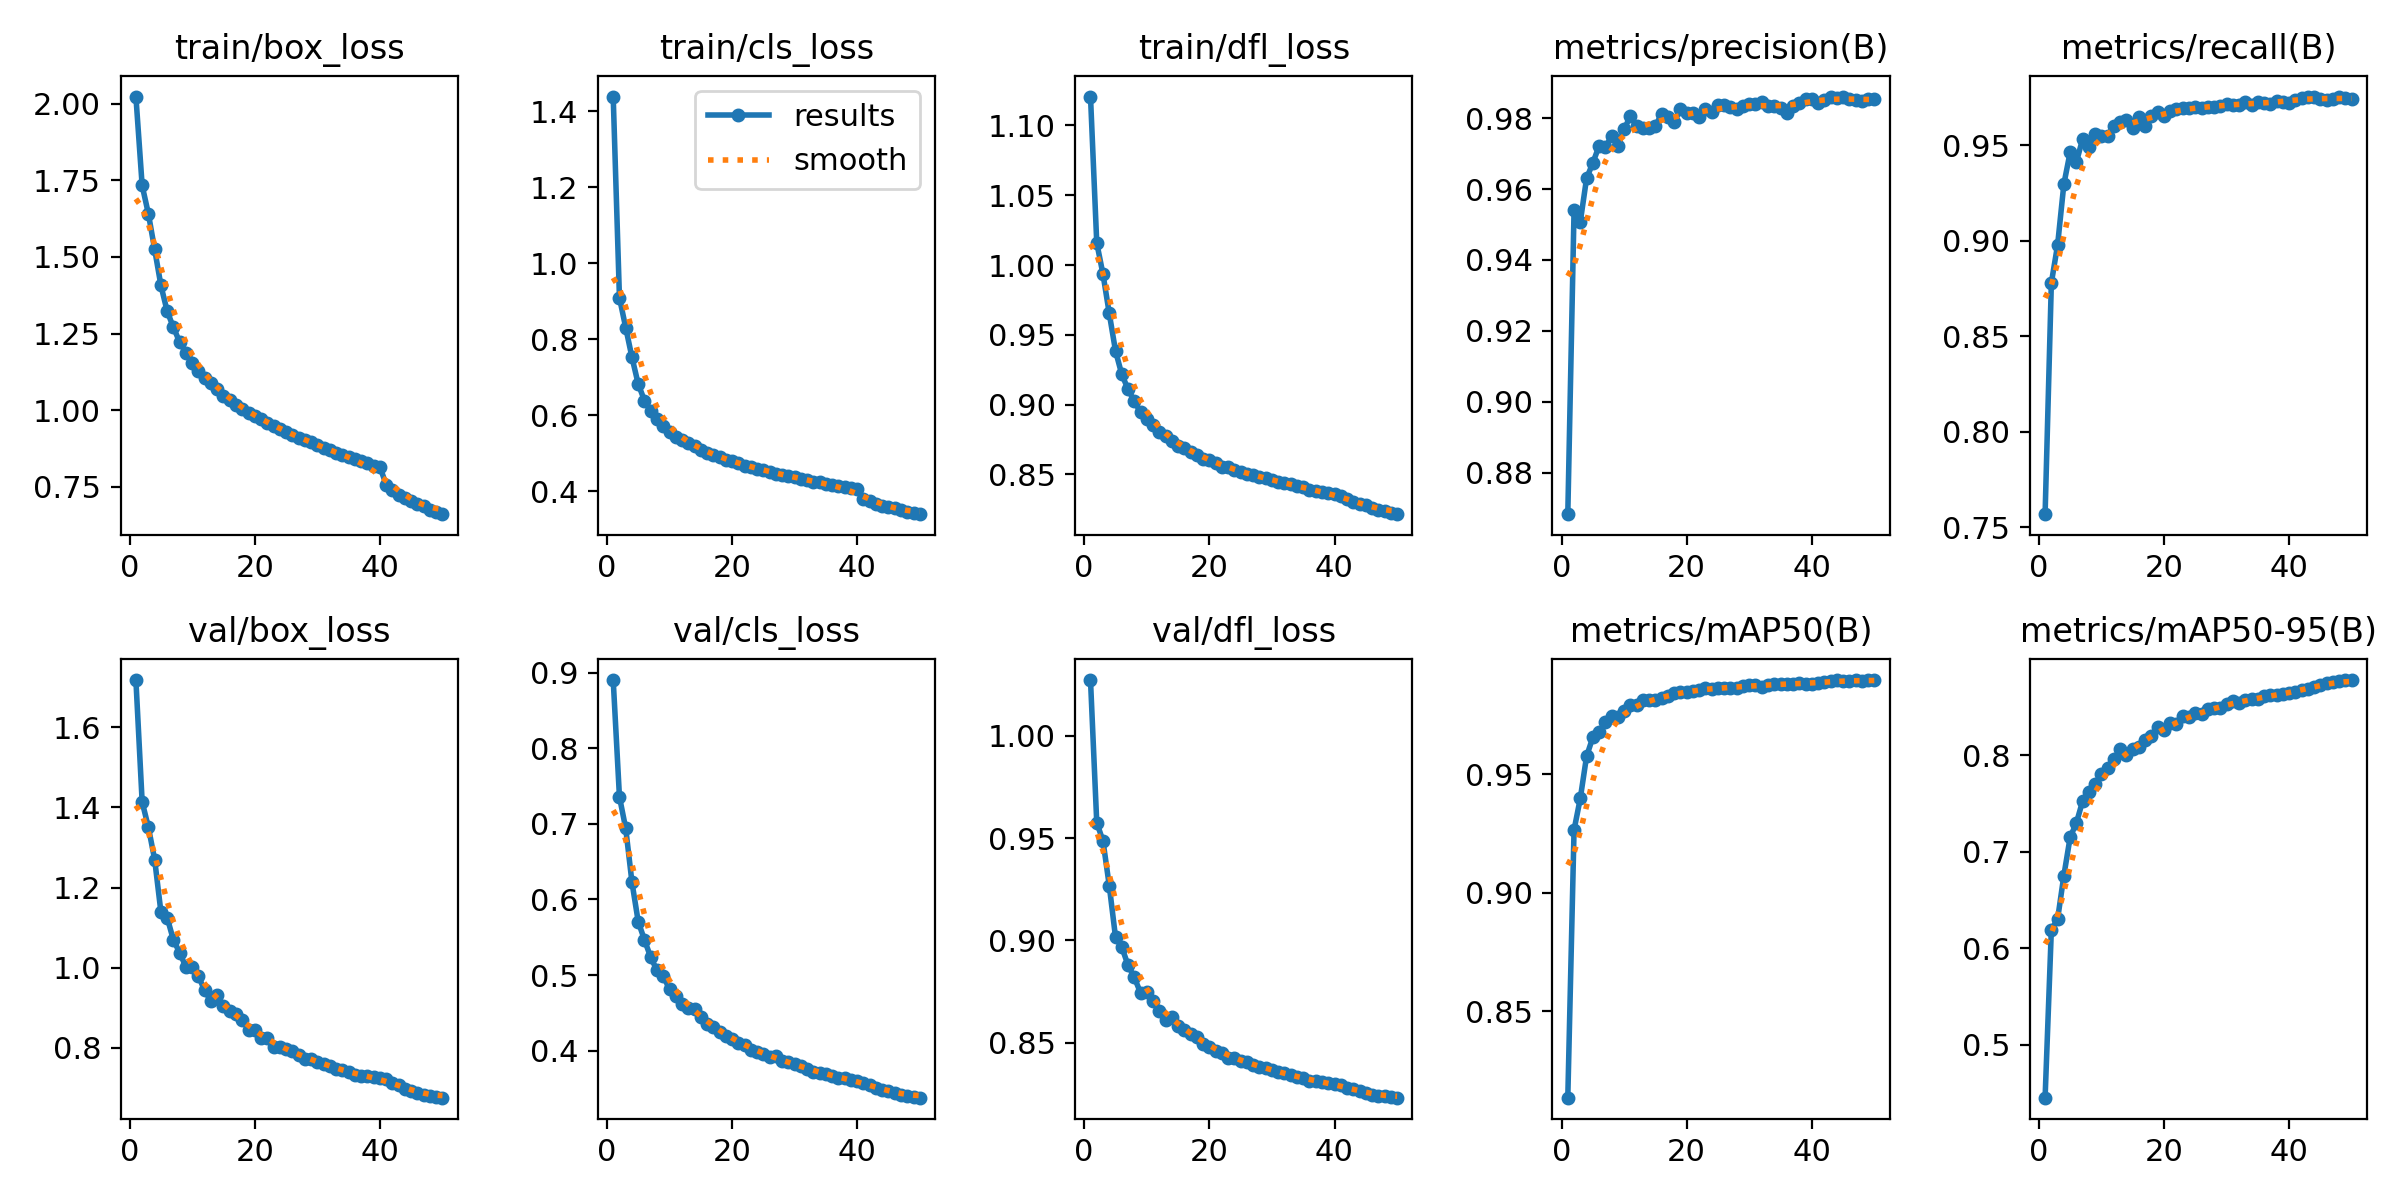

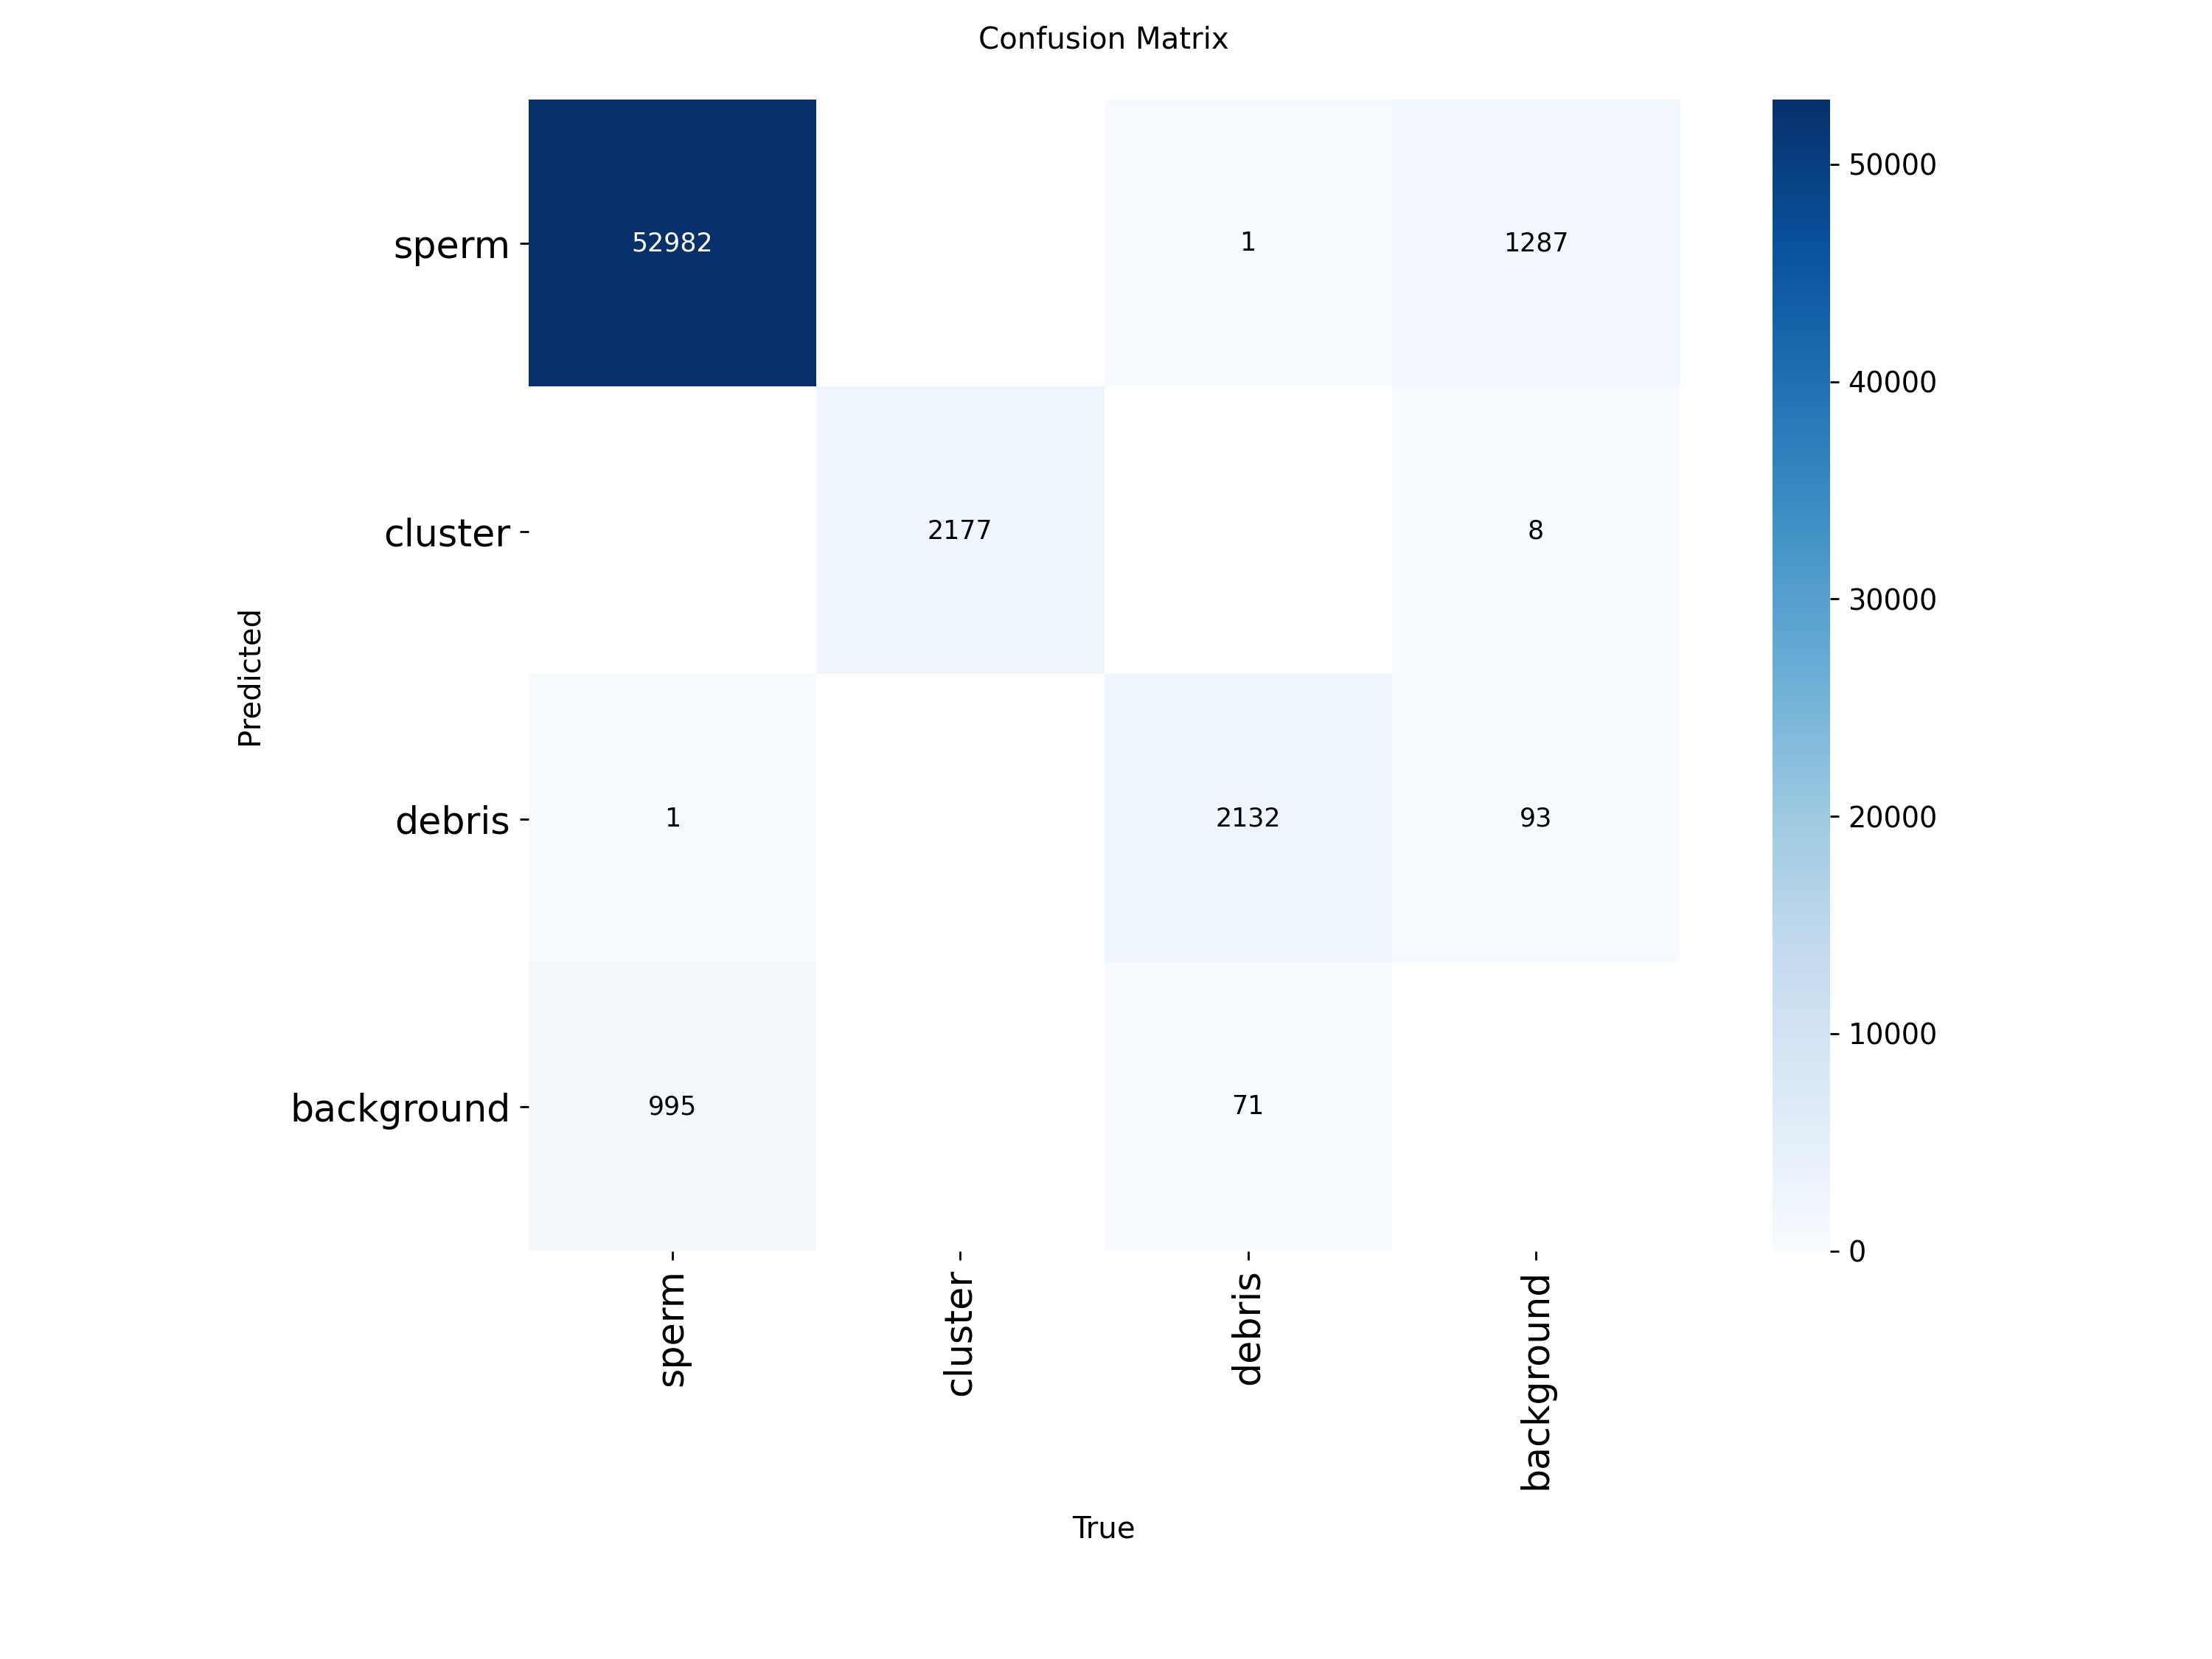

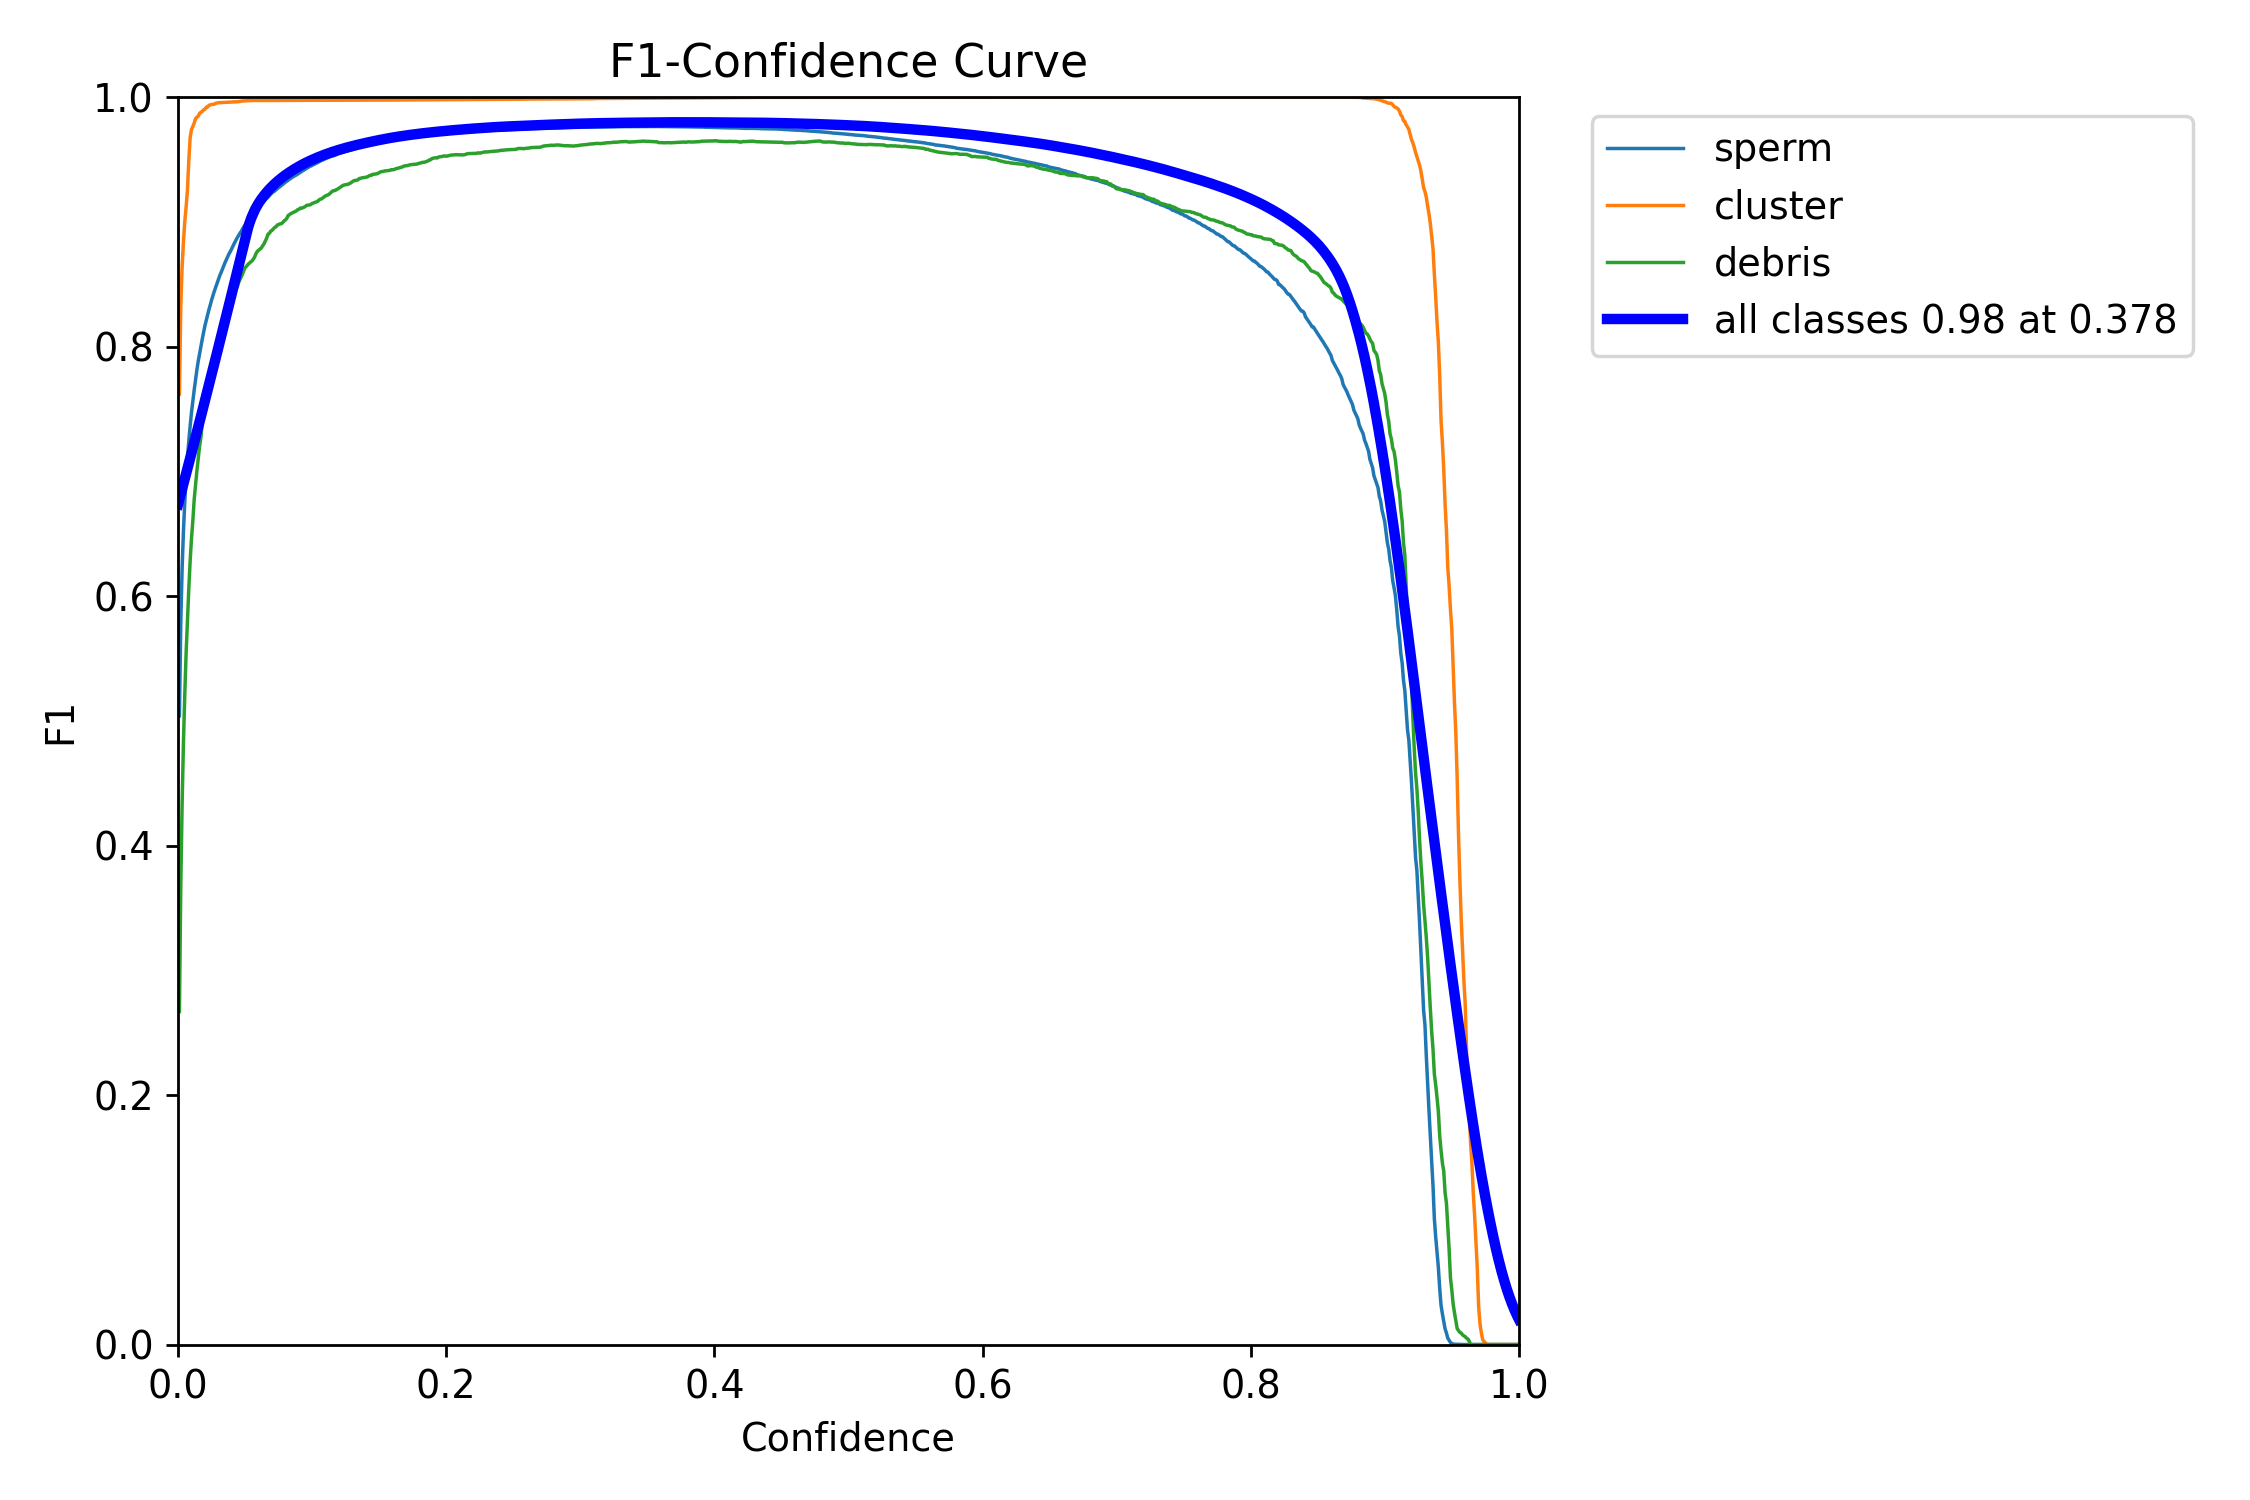

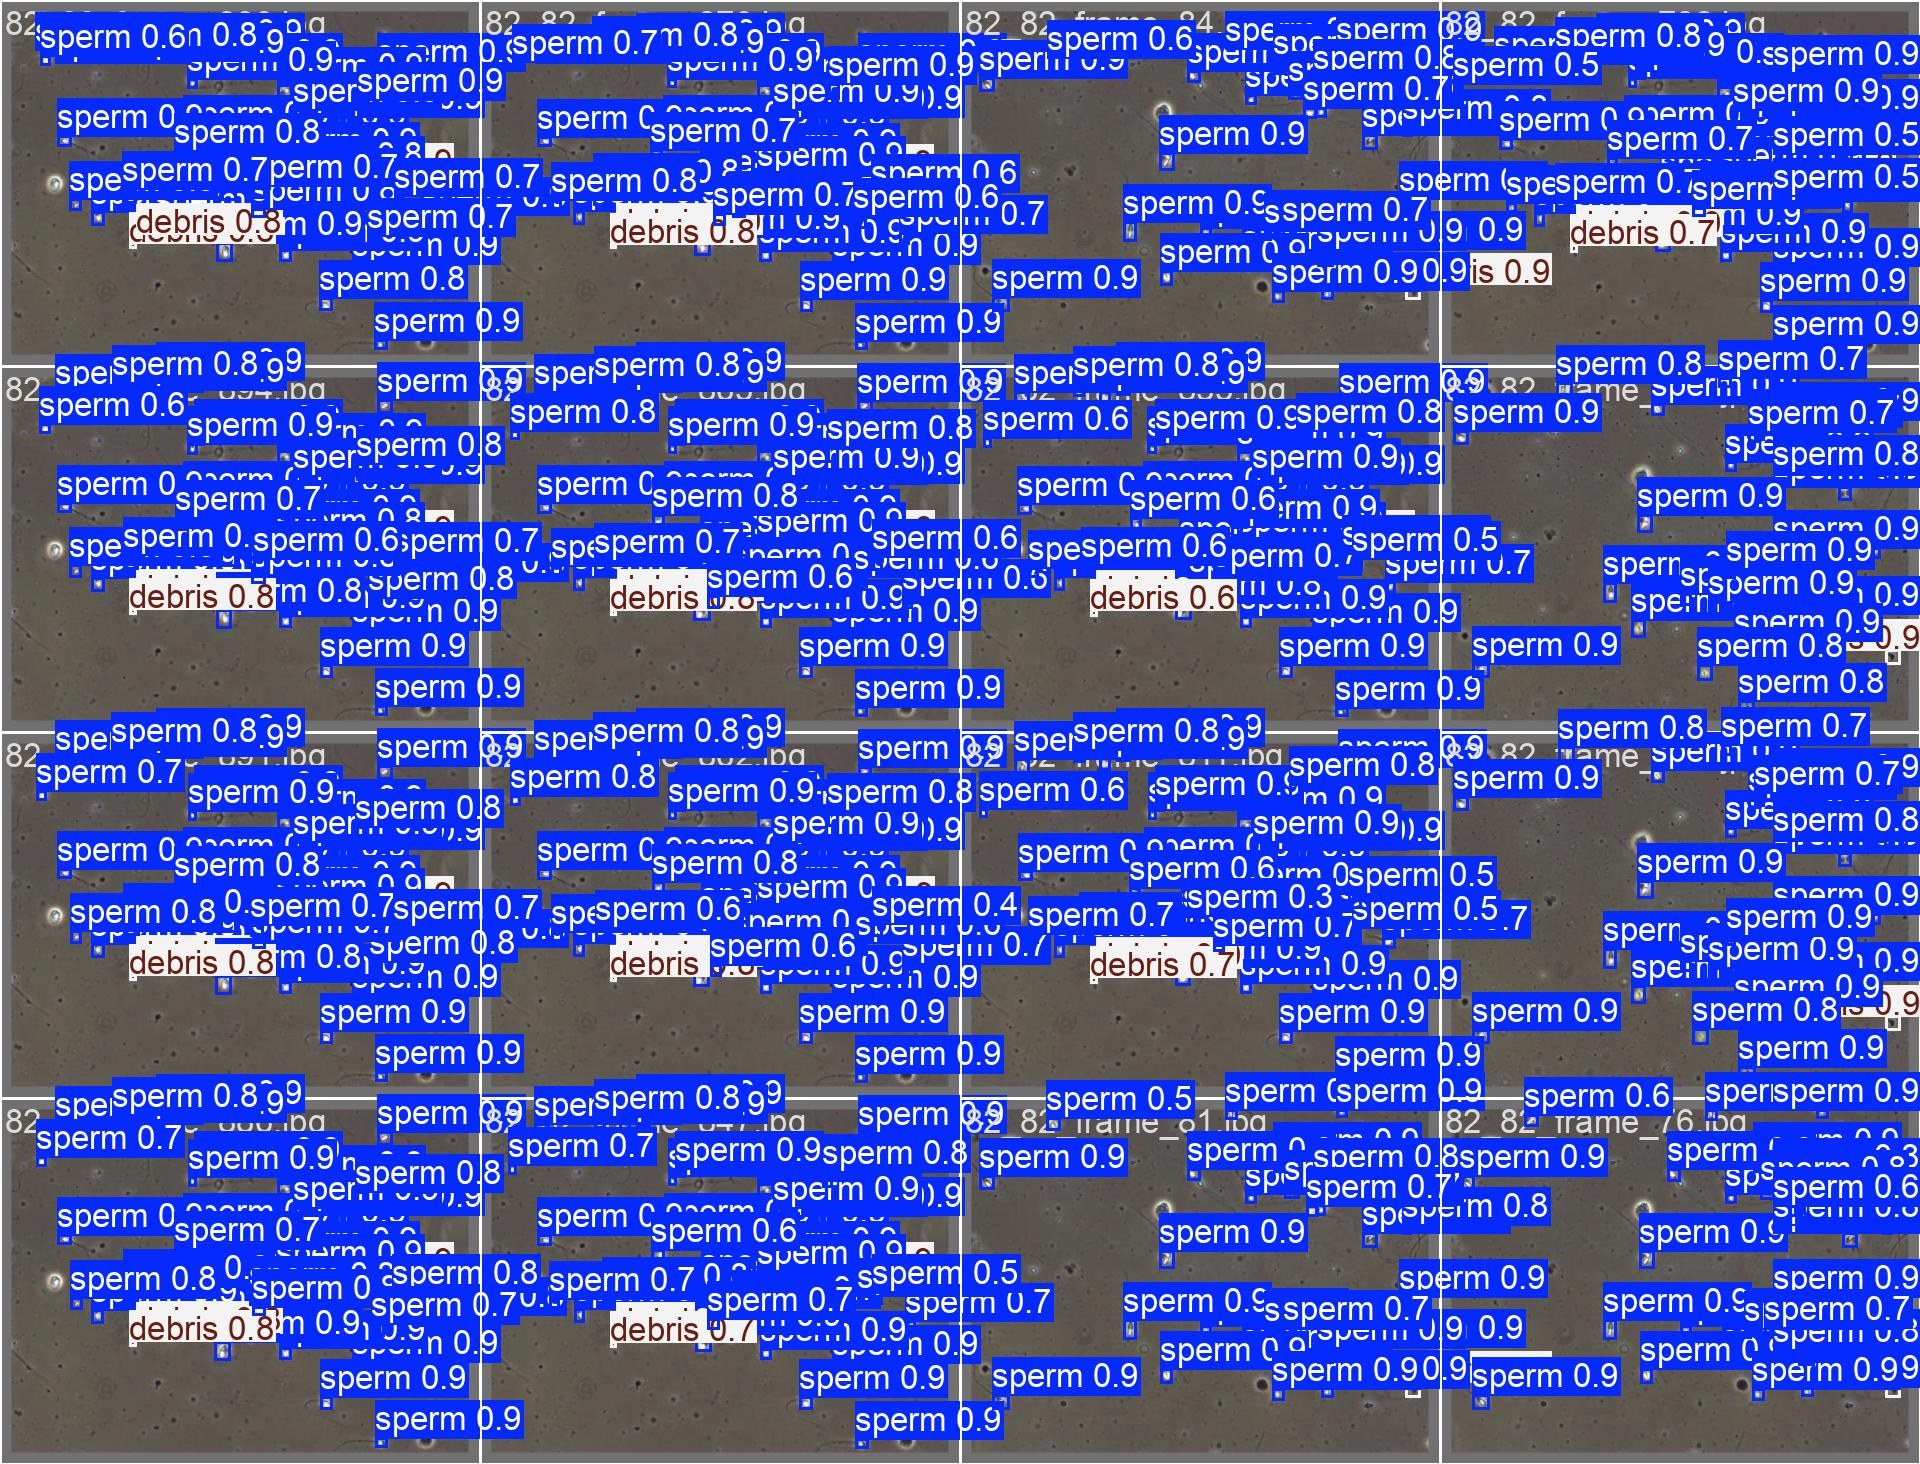

In [19]:
from IPython.display import Image, display, HTML

display(HTML("<h3>1. Grafik Performa (Loss & mAP)</h3>"))
display(Image(filename=r'runs/train_sperma_undersampled_cepat2/results.png', width=1000))

display(HTML("<hr><h3>2. Confusion Matrix (Tingkat Ketepatan)</h3>"))
display(Image(filename=r'runs/train_sperma_undersampled_cepat2/confusion_matrix.png', width=800))

display(HTML("<hr><h3>3. Keseimbangan Precision & Recall (F1-Curve)</h3>"))
# PERBAIKAN: Namanya adalah BoxF1_curve.png
display(Image(filename=r'runs/train_sperma_undersampled_cepat2/BoxF1_curve.png', width=800))

display(HTML("<hr><h3>4. Hasil Tebakan AI pada Lembar Ujian (Validation)</h3>"))
display(Image(filename=r'runs/train_sperma_undersampled_cepat2/val_batch0_pred.jpg', width=1000))
